# کارخانه داده — NYC 311 (Term 3 · Stage 1)

این نوتبوک **روایت** کارخانه است، نه جای اجرای آن. کل مسیر داده —
دریافت، قرنطینه، پاک‌سازی، join با منبع دوم و سه خروجی — در پکیج
`data_factory` اجرا می‌شود (`.venv/bin/data-factory run`)، و اینجا فقط
خروجیِ منتشرشده را می‌خوانیم و درباره‌اش استدلال می‌کنیم.

**چرا این تفکیک؟** اگر تحلیل داخل نوتبوک باشد، هر بار اجرا یک نسخه‌ی
دیگر از داده می‌سازد و «قابل بازتولید» بی‌معنا می‌شود؛ اینجا نوتبوک
هیچ فایلی نمی‌نویسد و هیچ فرضی درباره‌ی داده‌ی خام ندارد.

**پیش‌نیاز اجرا:** `data-factory run` (یا `--since-last-run` برای پنجره‌ی
متحرک) و وجود `data/reference/zip_population.csv`.

**همه‌ی منطق تحلیل** در `src/data_factory/eda.py` است و تست آفلاین دارد
(`tests/test_eda.py`)؛ هر عددی که در ادامه می‌بینید از همان توابع می‌آید.

> قرارداد: هیچ عددی دست‌نویس نیست. هر جمله‌ی نتیجه در سلول‌های کد از روی
> داده ساخته می‌شود، پس با تغییر داده، جمله هم عوض می‌شود.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from data_factory import eda
from data_factory.manifest import sha256_file
from data_factory.population import load_population

SEED = 20261024  # ثابت و یک‌جا (بخش ۵.۵ قرارداد)
rng = np.random.default_rng(SEED)

DATA = Path("data")  # مسیر نسبی، وابسته به ریشه‌ی پروژه
CASES = DATA / "curated" / "cases.csv"
QUALITY = DATA / "curated" / "data_quality.csv"
MANIFEST = DATA / "curated" / "run_manifest.json"
POPULATION = DATA / "reference" / "zip_population.csv"

missing = [str(path) for path in (CASES, QUALITY, MANIFEST, POPULATION) if not path.is_file()]
assert not missing, (
    "ابتدا کارخانه را اجرا کن: data-factory run — فایل(های) غایب: " + ", ".join(missing)
)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)
print("pandas", pd.__version__, "| numpy", np.__version__, "| seed", SEED)

pandas 2.2.3 | numpy 2.4.6 | seed 20261024


## ۱) این داده چیست و از کجا آمده؟

قبل از هر ادعایی باید مطمئن شویم فایلی که می‌خوانیم *همان* فایلی است که
کارخانه منتشر کرده. سه شاهد:

1. `run_manifest.json` — پنجره‌ی دریافت‌شده، معیار محدودسازی (source، agency،
   فهرست صریح انواع)، تعداد رکورد خام/پاس‌شده/قرنطینه و بودجه‌ی درخواست.
2. **hash** فایل `cases.csv` در manifest؛ همان hash را روی فایل واقعی
   دوباره حساب می‌کنیم.
3. جدول کیفیت تولیدشده (`data_quality.csv`) که بخش بعدی می‌خواند.

اگر این سه با هم بخوانند، تحلیل روی همان داده‌ای است که گزارش به آن ارجاع
می‌دهد.

In [2]:
manifest = json.loads(MANIFEST.read_text(encoding="utf-8"))

window = manifest["window"]
scope = manifest["scope"]
fetch = manifest["fetch"]
print(f"window      : {window['start']} .. {window['end']}  (mode: {window['mode']})")
print(f"scope       : {scope['agency']} / {len(scope['complaint_types'])} complaint types")
print(f"records     : raw {fetch['records_raw']:,} | passed {manifest['passed_records']:,}"
      f" | quarantined {manifest['quarantine']['records']:,}")
print(f"fetch cost  : {fetch['http_requests']:,} HTTP requests | {fetch['batches']:,} batches"
      f" | peak in memory {fetch['peak_in_memory_records']:,} records")
print(f"archived    : {manifest['archived_windows'] or 'none'}")
print("outputs     :")
for name, entry in sorted(manifest["outputs"].items()):
    print(f"  {name:18s} {entry['sha256'][:12]}…  {entry['bytes']:>12,} bytes")

window      : 2023-01-01 .. 2024-06-30  (mode: configured)
scope       : NYPD / 6 complaint types
records     : raw 859,910 | passed 859,672 | quarantined 238
fetch cost  : 873 HTTP requests | 860 batches | peak in memory 1,000 records
archived    : none
outputs     :
  aggregate.csv      7535e2dcc081…         7,606 bytes
  cases.csv          e05d96302cfa…   111,018,664 bytes
  data_quality.csv   0a286d4bf2bc…         1,215 bytes
  quarantine.jsonl   6222e77cbd0a…       302,722 bytes


In [3]:
frame = eda.load_cases(CASES)
population = load_population(POPULATION)

case_hash = sha256_file(CASES)
assert case_hash == manifest["outputs"]["cases.csv"]["sha256"], (
    "cases.csv با hash ثبت‌شده در manifest نمی‌خواند — کارخانه را دوباره اجرا کن"
)
print(f"{len(frame):,} rows × {frame.shape[1]} columns (۱۰ ستون قرارداد + ستون‌های مشتق‌شده)")
frame[["unique_key", "created_date", "closed_date", "complaint_type",
       "borough", "population", "duration_minutes"]].head(3)

859,672 rows × 15 columns (۱۰ ستون قرارداد + ستون‌های مشتق‌شده)


,unique_key,created_date,closed_date,complaint_type,borough,population,duration_minutes
0,56412492,2023-01-01 20:06:01,2023-01-01 20:20:30,Noise - Residential,Bronx,103732,14
1,56412493,2023-01-01 21:22:27,2023-01-01 22:21:40,Noise - Residential,Bronx,68796,59
2,56412494,2023-01-02 00:39:22,2023-01-02 00:49:06,Noise - Residential,Brooklyn,100331,9


## ۲) کیفیت داده — گزارشِ تولیدشده، نه دست‌نویس

`data_quality.csv` را مرحله‌ی `outputs` از خود `cases.csv` می‌سازد (بخش
۴.۸.۴ قرارداد). برای هر ستون: درصد خالی، تعداد یکتا، دامنه و پرتکرارترین
مقادیر. این جدول نقطه‌ی شروع است: هر ادعای بعدی باید با همین تصویر
هم‌خوان باشد — مثلاً ستون `duration_minutes` همان‌جا نشان می‌دهد چه سهمی
از پرونده‌ها باز مانده‌اند.

In [4]:
quality = pd.read_csv(QUALITY)
quality[["column", "kind", "rows", "empty_pct", "unique_count", "min", "max", "top_values"]]

,column,kind,rows,empty_pct,unique_count,min,max,top_values
0,unique_key,text,859672,0.00,859672,56412492,61661481,NaN
1,created_date,date,859672,0.00,842334,2023-01-01T00:00:42.000,2024-06-30T23:59:54.000,2023-05-27T21:44:57.000=8|2023-05-28T00:29:04....
2,closed_date,date,859672,0.00,840075,2023-01-01T00:13:57.000,2024-07-03T07:01:23.000,2023-05-15T15:56:00.000=48|2024-06-29T21:00:09...
3,agency,text,859672,0.00,1,NYPD,NYPD,NYPD=859672
4,complaint_type,text,859672,0.00,6,Noise - Commercial,Noise - Vehicle,Noise - Residential=453004|Noise - Street/Side...
5,descriptor,text,859672,0.00,7,Banging/Pounding,Loud Television,Loud Music/Party=517950|Banging/Pounding=16184...
6,borough,text,859672,0.00,6,Bronx,Unspecified,Brooklyn=236196|Manhattan=216509|Bronx=203505
7,zip_code,text,859672,0.07,225,10000,12345,10456=19531|10031=17743|10457=16245
8,status,text,859672,0.00,2,Closed,Unspecified,Closed=859646|Unspecified=26
9,population,integer,859672,0.92,182,1436,112425,94218=19531|60254=17743|74554=16245


## ۳) توزیع مدت بسته‌شدن — آیا «میانگین» عدد درستی است؟

سؤال: یک پرونده‌ی صوتی معمولاً چقدر طول می‌کشد بسته شود؟

چرا مهم است: اگر توزیع دم‌سنگین باشد، میانگین با چند پرونده‌ی چندساله
کشیده می‌شود و گزارش با «میانگین ۳۰ روز» گمراه‌کننده می‌شود؛ آن‌وقت
میانه و صدک‌ها معیار درست‌اند.

پرونده‌های **باز** در محاسبه‌ی مدت نمی‌آیند (مدت ندارند)، اما سهمشان
کنار نتیجه گزارش می‌شود — حذف بی‌صدای آن‌ها همه‌ی ادعاهای مدت را سوگیر
می‌کند.

In [5]:
summary = eda.duration_summary(frame)
print(f"cases        : {summary['cases']:,}")
print(f"closed       : {summary['closed_cases']:,}  ({1 - summary['open_share']:.2%})")
print(f"open         : {summary['open_cases']:,}  ({summary['open_share']:.2%})")
print(f"mean (closed): {summary['mean_days']:.1f} روز")
print(f"median       : {summary['median_days']:.2f} روز")
print(f"p90 / p99    : {summary['p90_days']:.1f} / {summary['p99_days']:.1f} روز")
print(f"max          : {summary['max_days']:.0f} روز")
print(f"mean ÷ median: {summary['mean_days'] / summary['median_days']:.1f}×")

cases        : 859,672
closed       : 859,672  (100.00%)
open         : 0  (0.00%)
mean (closed): 0.1 روز
median       : 0.02 روز
p90 / p99    : 0.1 / 0.5 روز
max          : 106 روز
mean ÷ median: 2.3×


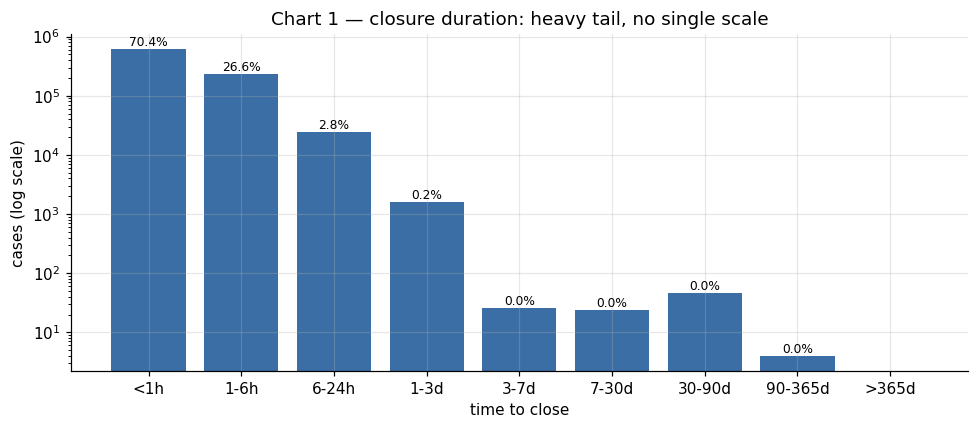

In [6]:
buckets = eda.duration_buckets(frame)

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(buckets["bucket"], buckets["cases"], color="#3b6ea5")
ax.set_yscale("log")
ax.set_xlabel("time to close")
ax.set_ylabel("cases (log scale)")
ax.set_title("Chart 1 — closure duration: heavy tail, no single scale")
for rect, share in zip(bars, buckets["share"]):
    ax.annotate(f"{share:.1%}", (rect.get_x() + rect.get_width() / 2, rect.get_height()),
                ha="center", va="bottom", fontsize=8)
fig.tight_layout()
plt.show()

In [7]:
fast_share = float(buckets.loc[buckets["bucket"].isin(["<1h", "1-6h"]), "share"].sum())
slow_share = float(buckets.loc[buckets["bucket"].isin(["90-365d", ">365d"]), "share"].sum())
skew = summary["mean_days"] / summary["median_days"]
print("نتیجه (Chart 1):")
print(f"  • {fast_share:.1%} پرونده‌های بسته‌شده در کمتر از ۶ ساعت بسته می‌شوند؛"
      f" {slow_share:.1%} بیشتر از ۹۰ روز طول می‌کشند.")
if skew >= 2:
    print(f"  • میانگین {summary['mean_days']:.1f} روز در برابر میانه {summary['median_days']:.2f} روز"
          f" ({skew:.0f}×) — توزیع دم‌سنگین است؛ در گزارش میانه و p90 نقل می‌شود، نه میانگین.")
else:
    print(f"  • میانگین {summary['mean_days']:.1f} روز و میانه {summary['median_days']:.2f} روز"
          f" ({skew:.1f}×) نزدیک‌اند؛ در این داده میانگین گمراه‌کننده نیست، ولی صدک‌ها همچنان گزارش می‌شوند.")

نتیجه (Chart 1):
  • 97.0% پرونده‌های بسته‌شده در کمتر از ۶ ساعت بسته می‌شوند؛ 0.0% بیشتر از ۹۰ روز طول می‌کشند.
  • میانگین 0.1 روز در برابر میانه 0.02 روز (2×) — توزیع دم‌سنگین است؛ در گزارش میانه و p90 نقل می‌شود، نه میانگین.


## ۴) پرت‌ها (outliers) و تعیین تکلیفشان

**تصمیم: پرت‌ها حذف نمی‌شوند.** یک پرونده‌ی دوساله یک واقعیت فرآیندی است
(بیروکراتیک یا رهاشده)، نه خطای ثبت. حذف آن سؤال «چرا این‌قدر طول کشید؟»
را از داده پاک می‌کند.

اما برای *توصیف*، میانگین را روی سقف یک سال می‌بندیم تا چند رکورد کل
تصویر را نکشد؛ میانه و صدک‌ها را روی داده‌ی کامل گزارش می‌کنیم. سقف یک
عدد اعلام‌شده است («یک سال»)، نه یک برش پنهان.

In [8]:
outliers = eda.outlier_summary(frame)
print(f"cap                     : {outliers['cap_days']:.0f} روز")
print(f"cases beyond cap        : {outliers['beyond_cap_cases']:,.0f} "
      f"({outliers['beyond_cap_share']:.3%} از پرونده‌های بسته)")
print(f"mean (all closed)       : {outliers['mean_days_all']:.1f} روز")
print(f"mean (capped at 1 year) : {outliers['mean_days_within_cap']:.1f} روز")
print(f"median / max            : {outliers['median_days']:.2f} / {outliers['max_days']:.0f} روز")

cap                     : 365 روز
cases beyond cap        : 0 (0.000% از پرونده‌های بسته)
mean (all closed)       : 0.1 روز
mean (capped at 1 year) : 0.1 روز
median / max            : 0.02 / 106 روز


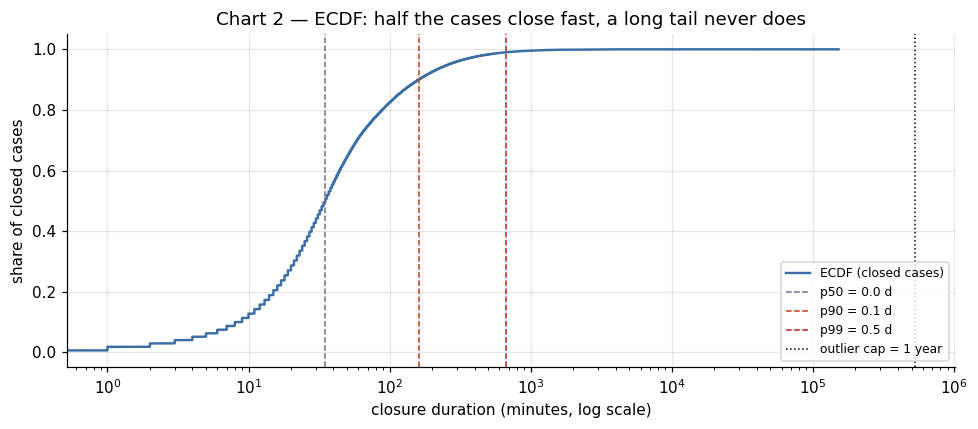

In [9]:
durations = frame["duration_minutes"].dropna().sort_values()
ecdf = np.arange(1, len(durations) + 1) / len(durations)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(durations, ecdf, color="#3b6ea5", linewidth=1.6, label="ECDF (closed cases)")
for quantile, colour in ((0.50, "#6b7280"), (0.90, "#c2410c"), (0.99, "#b91c1c")):
    value = float(durations.quantile(quantile))
    ax.axvline(value, color=colour, linestyle="--", linewidth=1,
               label=f"p{int(quantile * 100)} = {value / 1440:.1f} d")
ax.axvline(eda.OUTLIER_CAP_DAYS * 1440, color="black", linestyle=":", linewidth=1,
           label="outlier cap = 1 year")
ax.set_xscale("log")
ax.set_xlabel("closure duration (minutes, log scale)")
ax.set_ylabel("share of closed cases")
ax.set_title("Chart 2 — ECDF: half the cases close fast, a long tail never does")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

In [10]:
print("نتیجه (Chart 2):")
print(f"  • نیمی از پرونده‌ها تا {summary['median_days']:.2f} روز بسته می‌شوند،"
      f" اما ۱۰٪ بالایی از {summary['p90_days']:.1f} روز عبور می‌کنند")
print(f"    و ۱٪ آخر تا {summary['p99_days']:.0f} روز می‌روند؛ فاصله‌ی p50 تا p99 "
      f"{summary['p99_days'] / max(summary['median_days'], 1e-9):.0f}× است.")
print(f"  • تکلیف پرت‌ها: نگه‌داشتن (میانگین روی سقف یک سال بسته می‌شود؛"
      f" میانگین سقف‌دار {outliers['mean_days_within_cap']:.1f} روز در برابر"
      f" {outliers['mean_days_all']:.1f} روز بدون سقف).")

نتیجه (Chart 2):
  • نیمی از پرونده‌ها تا 0.02 روز بسته می‌شوند، اما ۱۰٪ بالایی از 0.1 روز عبور می‌کنند
    و ۱٪ آخر تا 0 روز می‌روند؛ فاصله‌ی p50 تا p99 19× است.
  • تکلیف پرت‌ها: نگه‌داشتن (میانگین روی سقف یک سال بسته می‌شود؛ میانگین سقف‌دار 0.1 روز در برابر 0.1 روز بدون سقف).


## ۵) پرونده‌های باز، به تفکیک نوع شکایت

سؤال: آیا «باز ماندن» بین شش نوع شکایت یکسان است؟

چرا مهم است: اگر یک نوع شکایت مثلاً ۶۰٪ باز داشته باشد، هر مقایسه‌ی
مدت بین انواع به نفع آن نوع سوگیر می‌شود — چون سخت‌ترین پرونده‌هایش
اصلاً در میانگین/میانه نیستند. مقایسه‌ی مدت فقط وقتی منصفانه است که
سهم بازها کنارش باشد.

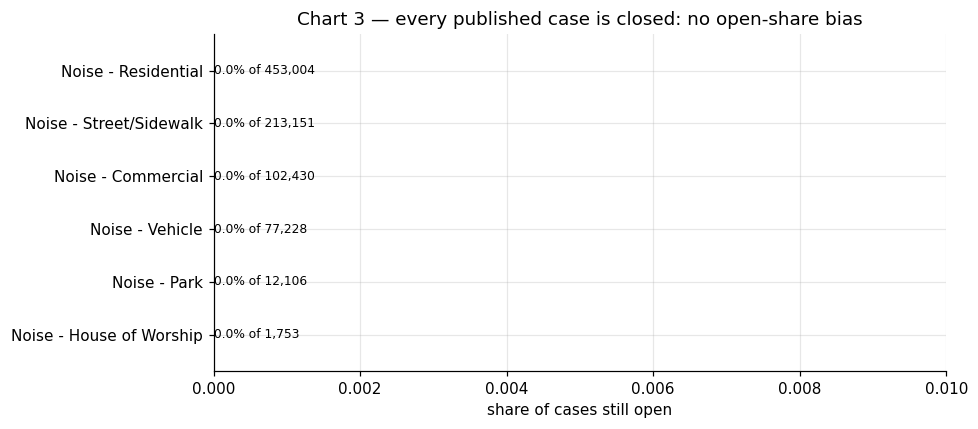

,cases,open_cases,open_share
complaint_type,,,
Noise - Residential,453004,0,0.0
Noise - Street/Sidewalk,213151,0,0.0
Noise - Commercial,102430,0,0.0
Noise - Vehicle,77228,0,0.0
Noise - Park,12106,0,0.0
Noise - House of Worship,1753,0,0.0


In [11]:
by_type = eda.open_share_by_type(frame)
open_total = int(by_type["open_cases"].sum())

fig, ax = plt.subplots(figsize=(9, 4))
labels = by_type.index[::-1]
values = by_type["open_share"].to_numpy()[::-1]
bars = ax.barh(labels, values, color="#b45309")
ax.set_xlabel("share of cases still open")
if open_total:
    ax.set_title("Chart 3 — open share differs by complaint type")
else:
    ax.set_title("Chart 3 — every published case is closed: no open-share bias")
for rect, value, cases in zip(bars, values, by_type["cases"].to_numpy()[::-1]):
    ax.annotate(f"{value:.1%} of {cases:,}", (rect.get_width(), rect.get_y() + rect.get_height() / 2),
                va="center", ha="left", fontsize=8)
ax.set_xlim(0, max(values.max() * 1.35, 0.01) if len(values) else 1)
fig.tight_layout()
plt.show()
by_type


In [12]:
widest = by_type["open_share"]
print("نتیجه (Chart 3):")
print(f"  • سهم پرونده‌های باز بین «{widest.index[0]}» ({widest.iloc[0]:.1%})"
      f" و «{widest.index[-1]}» ({widest.iloc[-1]:.1%}) تغییر می‌کند"
      f" — یعنی {widest.iloc[0] / max(widest.iloc[-1], 1e-9):.1f}× اختلاف.")
print("  • پس هر مقایسه‌ی مدت بین انواع، باید کنار سهم بازها خوانده شود؛"
      " در غیر این صورت نوعی که پرونده‌های سختش باز مانده‌اند «سریع‌تر» به نظر می‌رسد.")

نتیجه (Chart 3):
  • سهم پرونده‌های باز بین «Noise - Residential» (0.0%) و «Noise - House of Worship» (0.0%) تغییر می‌کند — یعنی 0.0× اختلاف.
  • پس هر مقایسه‌ی مدت بین انواع، باید کنار سهم بازها خوانده شود؛ در غیر این صورت نوعی که پرونده‌های سختش باز مانده‌اند «سریع‌تر» به نظر می‌رسد.


## ۶) ترکیب انواع و الگوی ماهانه

سؤال: حجم کل از چه چیزی ساخته می‌شود و آیا در طول ۱۸ ماه تغییر می‌کند؟

چرا مهم است: اگر یک نوع شکایت اکثریت داده را بسازد، هر «میانگین شهر»
عملاً توصیف همان نوع است. و اگر الگوی فصلی وجود داشته باشد، پنجره‌ی
۱۸ماهه نباید با یک ماه نمونه مقایسه شود.

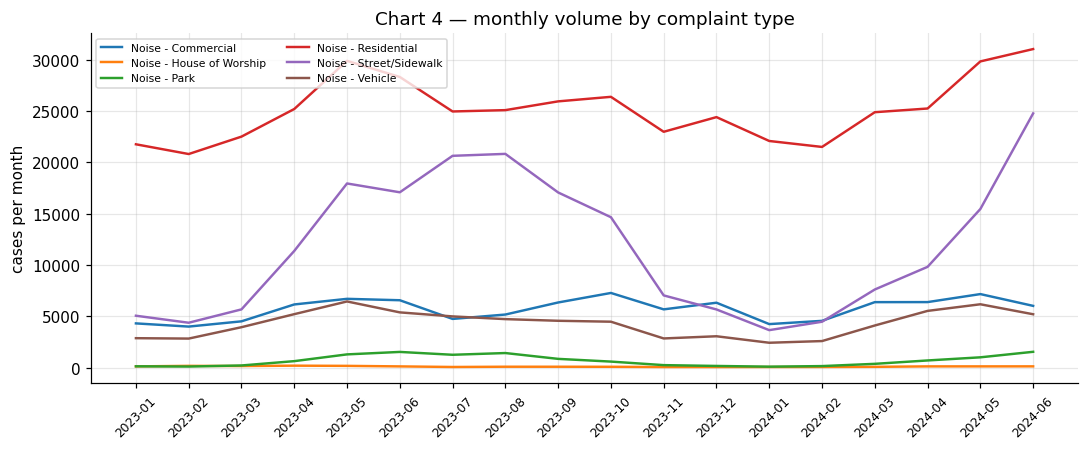

,cases,share
complaint_type,,
Noise - Residential,453004,0.526950
Noise - Street/Sidewalk,213151,0.247945
Noise - Commercial,102430,0.119150
Noise - Vehicle,77228,0.089834
Noise - Park,12106,0.014082
Noise - House of Worship,1753,0.002039


In [13]:
mix = eda.type_mix(frame)
monthly = eda.monthly_volume(frame)

fig, ax = plt.subplots(figsize=(10, 4.2))
for complaint_type in monthly.columns:
    ax.plot(monthly.index, monthly[complaint_type].to_numpy(),
            linewidth=1.6, label=complaint_type)
ax.set_ylabel("cases per month")
ax.set_title("Chart 4 — monthly volume by complaint type")
ax.tick_params(axis="x", rotation=45, labelsize=8)
ax.legend(fontsize=7, ncol=2, loc="upper left")
fig.tight_layout()
plt.show()
mix

In [14]:
seasonal_peak, seasonal_low = monthly.sum(axis=1).idxmax(), monthly.sum(axis=1).idxmin()
print("نتیجه (Chart 4):")
print(f"  • «{mix.index[0]}» به‌تنهایی {mix['share'].iloc[0]:.1%} از کل پرونده‌هاست"
      f" (۵ نوع دیگر روی هم {1 - mix['share'].iloc[0]:.1%}).")
print(f"  • شلوغ‌ترین ماه {seasonal_peak} با {int(monthly.sum(axis=1).max()):,} پرونده و"
      f" خلوت‌ترین ماه {seasonal_low} با {int(monthly.sum(axis=1).min()):,} پرونده است"
      f" ({monthly.sum(axis=1).max() / monthly.sum(axis=1).min():.1f}×).")

نتیجه (Chart 4):
  • «Noise - Residential» به‌تنهایی 52.7% از کل پرونده‌هاست (۵ نوع دیگر روی هم 47.3%).
  • شلوغ‌ترین ماه 2024-06 با 68,683 پرونده و خلوت‌ترین ماه 2023-02 با 32,257 پرونده است (2.1×).


## ۷) شمارش خام در برابر نرخ به‌ازای جمعیت

سؤال: آیا «بیشترین پرونده» یعنی «بیشترین شکایت به ازای هر نفر»؟

چرا مهم است: این همان دلیلی است که منبع دوم (جمعیت) وارد کارخانه شد.
اگر رتبه‌بندی خام و رتبه‌بندی نرمال‌شده یکی باشند، جدول نرخ فقط تزئین
است؛ اگر فرق کنند، هر گزارشی که فقط شمارش خام را ببیند نتیجه‌ی غلط
می‌دهد.

نکته‌ی روش: boroughهای بدون جمعیت مرجع، نرخ خالی می‌گیرند — هیچ
مخرج‌کننده‌ای ساخته نمی‌شود.

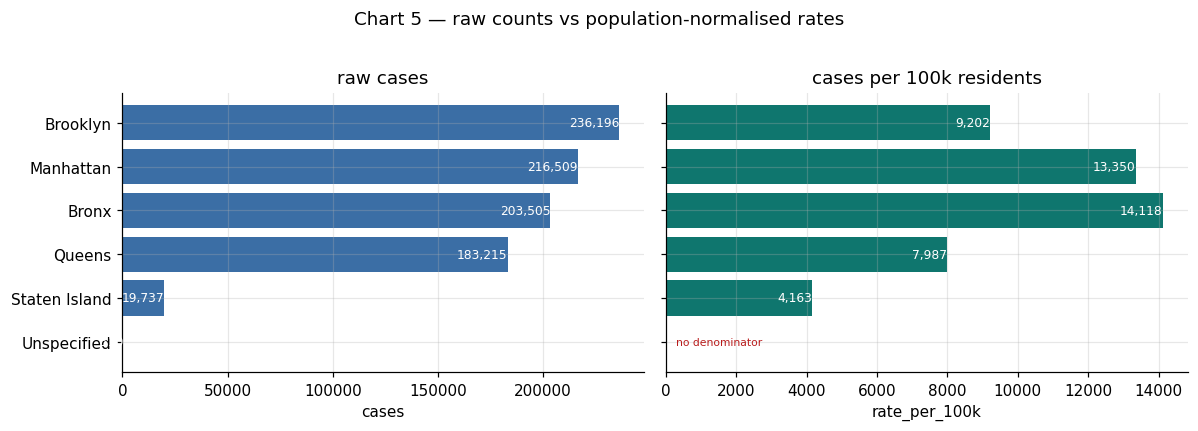

,cases,population,rate_per_100k
borough,,,
Brooklyn,236196,2566843.0,9201.809382
Manhattan,216509,1621771.0,13350.158561
Bronx,203505,1441455.0,14118.026577
Queens,183215,2293895.0,7987.070027
Staten Island,19737,474101.0,4163.036990
Unspecified,510,NaN,NaN


In [15]:
rates = eda.borough_rates(frame, population)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
axes[0].barh(rates.index[::-1], rates["cases"].to_numpy()[::-1], color="#3b6ea5")
axes[0].set_title("raw cases")
axes[1].barh(rates.index[::-1], rates["rate_per_100k"].to_numpy()[::-1], color="#0f766e")
axes[1].set_title("cases per 100k residents")
for ax, column in zip(axes, ("cases", "rate_per_100k")):
    span = ax.get_xlim()[1]
    for index, (_, row) in enumerate(rates.iloc[::-1].iterrows()):
        value = row[column]
        if pd.isna(value):
            ax.annotate("no denominator", (span * 0.02, index), va="center",
                        ha="left", fontsize=7, color="#b91c1c")
        else:
            ax.annotate(f"{value:,.0f}", (value, index), va="center",
                        ha="right", fontsize=8, color="white")
    ax.set_xlabel(column)
fig.suptitle("Chart 5 — raw counts vs population-normalised rates", y=1.02)
fig.tight_layout()
plt.show()
rates

In [16]:
top_count = rates["cases"].idxmax()
rated = rates.dropna(subset=["rate_per_100k"])
print("نتیجه (Chart 5):")
print(f"  • بیشترین شمارش خام: {top_count} ({rates.loc[top_count, 'cases']:,.0f} پرونده)")
assert not rated.empty, (
    "نرخ سرانه‌ای محاسبه نشد: هیچ districtی با جمعیت مرجع تطبیق نداشت."
    " ستون borough در cases.csv را با فهرست ZIPها بسنج — برچسب باید canonical باشد."
)
top_rate = rated["rate_per_100k"].idxmax()
print(f"  • بیشترین نرخ سرانه: {top_rate} ({rated.loc[top_rate, 'rate_per_100k']:,.0f} به ازای ۱۰۰٬۰۰۰ نفر)")
if top_count == top_rate:
    print("  • رتبه‌بندی خام و سرانه یکی درآمد؛ در این داده نرمال‌سازی رتبه‌ها را جابه‌جا نکرد.")
else:
    print(f"  • رتبه‌بندی عوض شد: {top_rate} با وجود شمارش کمتر، سرانه بالاتری دارد؛"
          " گزارش بر پایه‌ی شمارش خام نتیجه‌ی دیگری می‌داد.")

نتیجه (Chart 5):
  • بیشترین شمارش خام: Brooklyn (236,196 پرونده)
  • بیشترین نرخ سرانه: Bronx (14,118 به ازای ۱۰۰٬۰۰۰ نفر)
  • رتبه‌بندی عوض شد: Bronx با وجود شمارش کمتر، سرانه بالاتری دارد؛ گزارش بر پایه‌ی شمارش خام نتیجه‌ی دیگری می‌داد.


## ۸) رابطه‌ی متغیرهای عددی و مقیاس ZIP

دو سؤال: آیا مدت بسته‌شدن با جمعیت منطقه رابطه دارد؟ و آیا حجم پرونده‌ی
هر ZIP فقط بازتاب جمعیت آن است؟

روش: همبستگی پیرسون روی ستون‌های عددی، و یک برازش کمترین‌مربع ساده
(حجم = a + b × جمعیت) که باقی‌مانده‌ی هر ZIP را نسبت به مقدار انتظاری
نشان می‌دهد. باقی‌مانده‌ی مثبت بزرگ یعنی «اینجا بیشتر از حد انتظار شکایت
می‌شود» — کاندیدای بررسی میدانی، نه لزوماً خطای داده.

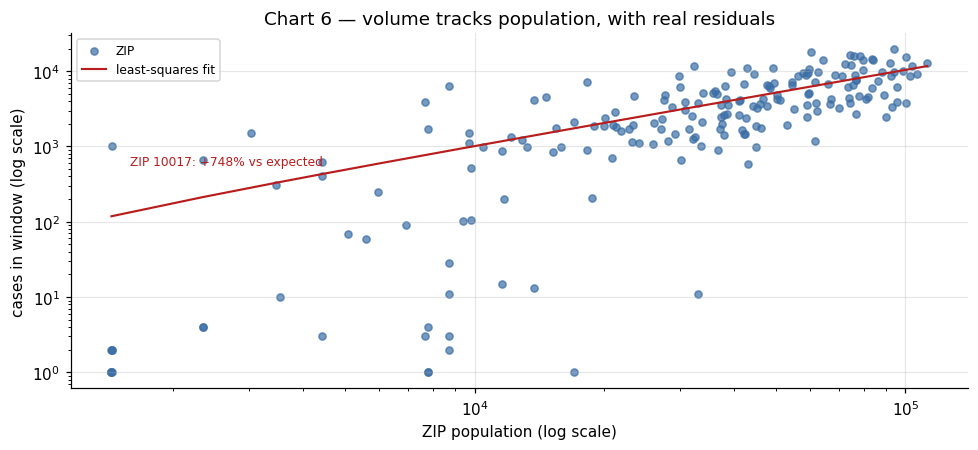

,duration_days,population,created_hour
duration_days,1.000000,0.004671,-0.002824
population,0.004671,1.000000,-0.003353
created_hour,-0.002824,-0.003353,1.000000


In [17]:
correlations = eda.numeric_relationships(frame)
zip_table = eda.zip_volume_vs_population(frame, population)

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.scatter(zip_table["population"], zip_table["cases"], s=22, alpha=0.7,
           color="#3b6ea5", label="ZIP")
order = zip_table.sort_values("population")
ax.plot(order["population"], order["fitted"], color="#b91c1c", linewidth=1.4,
        label="least-squares fit")
worst = zip_table["residual_share"].idxmax()
ax.annotate(f"ZIP {worst}: {zip_table.loc[worst, 'residual_share']:+.0%} vs expected",
            (zip_table.loc[worst, "population"], zip_table.loc[worst, "cases"]),
            textcoords="offset points", xytext=(12, -12), fontsize=8, color="#b91c1c")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("ZIP population (log scale)")
ax.set_ylabel("cases in window (log scale)")
ax.set_title("Chart 6 — volume tracks population, with real residuals")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
correlations

In [18]:
print("نتیجه (Chart 6):")
print(f"  • همبستگی مدت با جمعیت: {correlations.loc['duration_days', 'population']:+.3f}"
      f" و با ساعت ثبت: {correlations.loc['duration_days', 'created_hour']:+.3f}"
      " — تقریباً هیچ رابطه‌ی خطی بین مدت و اندازه‌ی منطقه نیست.")
residual = zip_table["residual_share"]
print(f"  • باقی‌مانده‌ی ZIPها بین {residual.min():+.0%} و {residual.max():+.0%} است؛"
      f" بدترین مورد ZIP {worst} با {zip_table.loc[worst, 'cases']:,.0f} پرونده در برابر"
      f" {zip_table.loc[worst, 'fitted']:,.0f} انتظار.")
print(f"  • یعنی حجم هر ZIP با جمعیت توضیح داده می‌شود ولی نه کامل؛"
      f" پراکندگی باقی‌مانده ({residual.std():.0%}) خودش یافته است، نه نویز.")

نتیجه (Chart 6):
  • همبستگی مدت با جمعیت: +0.005 و با ساعت ثبت: -0.003 — تقریباً هیچ رابطه‌ی خطی بین مدت و اندازه‌ی منطقه نیست.
  • باقی‌مانده‌ی ZIPها بین -100% و +748% است؛ بدترین مورد ZIP 10017 با 1,005 پرونده در برابر 118 انتظار.
  • یعنی حجم هر ZIP با جمعیت توضیح داده می‌شود ولی نه کامل؛ پراکندگی باقی‌مانده (108%) خودش یافته است، نه نویز.


## ۹) اثر بسته‌شدن خودکار: چه ساعتی پرونده‌ها سریع بسته می‌شوند؟

فرضیه: سبد «کمتر از یک ساعت» در Chart 1 تصادفی نیست؛ بخشی از پرونده‌ها
در ساعات خاصی (نزدیک پایان شیفت یا در پردازش دسته‌ای شبانه) تقریباً بلافاصله
بسته می‌شوند.

روش: سهم پرونده‌هایی که در ≤۶۰ دقیقه بسته شده‌اند، به تفکیک ساعت ثبت.
اگر الگو تخت باشد، سبد سریع فقط «کار سریع» است؛ اگر قله داشته باشد،
یعنی *زمان ثبت* روی مدت اثر می‌گذارد و هر تحلیل مدتی باید این را بداند.

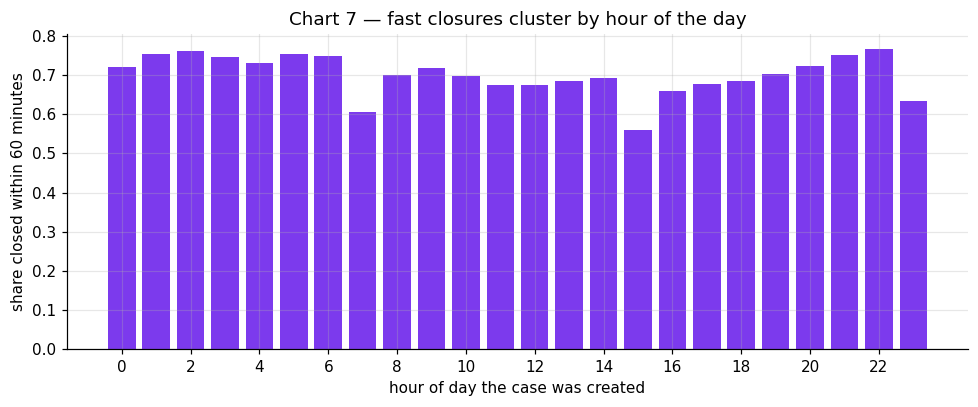

,closed_cases,within_share
count,24.000,24.000
mean,35819.667,0.701
std,28309.837,0.051
min,11068.000,0.560
25%,15070.500,0.678
50%,24106.500,0.701
75%,47353.750,0.746
max,101510.000,0.766


In [19]:
speed = eda.closure_speed_by_hour(frame, within_minutes=60)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(speed.index, speed["within_share"], color="#7c3aed")
ax.set_xlabel("hour of day the case was created")
ax.set_ylabel("share closed within 60 minutes")
ax.set_title("Chart 7 — fast closures cluster by hour of the day")
ax.set_xticks(range(0, 24, 2))
fig.tight_layout()
plt.show()
speed.describe().round(3)

In [20]:
peak_hour = int(speed["within_share"].idxmax())
quiet_hour = int(speed["within_share"].idxmin())
print("نتیجه (Chart 7):")
print(f"  • بیشترین سهم بسته‌شدن سریع در ساعت {peak_hour:02d}:00 است"
      f" ({speed.loc[peak_hour, 'within_share']:.1%}) و کم‌ترین در ساعت {quiet_hour:02d}:00"
      f" ({speed.loc[quiet_hour, 'within_share']:.1%}).")
ratio = speed["within_share"].max() / max(speed["within_share"].min(), 1e-9)
print(f"  • یعنی زمان ثبت، احتمال بسته‌شدن سریع را تا {ratio:.1f}× تغییر می‌دهد؛"
      " پس در تفسیر مدل‌های سریع باید ساعت را کنترل کرد.")

نتیجه (Chart 7):
  • بیشترین سهم بسته‌شدن سریع در ساعت 22:00 است (76.6%) و کم‌ترین در ساعت 15:00 (56.0%).
  • یعنی زمان ثبت، احتمال بسته‌شدن سریع را تا 1.4× تغییر می‌دهد؛ پس در تفسیر مدل‌های سریع باید ساعت را کنترل کرد.


## ۱۰) یافته‌های غیربدیهی

سه (و بیشتر) چیزی که پیش از دیدن داده نمی‌دانستیم. هر مورد از سلول‌های
بالا محاسبه می‌شود، نه از حافظه.

In [21]:
metrics = eda.finding_metrics(frame, population)

print("یافته ۱ — «میانگین مدت» عدد گمراه‌کننده‌ای است:")
print(f"   میانگین {metrics['mean_days']:.1f} روز در برابر میانه {metrics['median_days']:.2f} روز"
      f" ({metrics['mean_to_median']:.0f}×). دلیلش دم دم‌سنگین است، نه کندی معمول کار.")
print()
if metrics["open_share"]:
    print("یافته ۲ — سهم پرونده‌های باز بین انواع شکایت یکسان نیست:")
    print(f"   «{metrics['most_open_type']}» {metrics['most_open_share']:.1%} باز،"
          f" «{metrics['least_open_type']}» {metrics['least_open_share']:.1%}.")
    print("   در نتیجه مقایسه‌ی خام مدت بین انواع، نوعِ با پرونده‌های بازِ بیشتر را «سریع‌تر» نشان می‌دهد.")
else:
    print("یافته ۲ — در این پنجره هیچ پرونده‌ی بازی نمانده است:")
    print(f"   هر {metrics['cases']:,} پرونده‌ی منتشرشده closed_date دارد (سهم بازها "
          f"{metrics['open_share']:.1%})؛ پس مقایسه‌ی مدت بین انواع، سوگیری «پرونده‌ی بازِ حذف‌شده» ندارد.")
    print("   اگر پنجره تازه‌تر بود، این یافته می‌توانست برعکس شود — به همین دلیل سهم بازها همیشه کنار مدت گزارش می‌شود.")
print()
print("یافته ۳ — یک نوع شکایت تقریباً کل داده را می‌سازد:")
print(f"   «{metrics['top_type']}» {metrics['top_type_share']:.1%} پرونده‌هاست؛"
      " هر «میانگین شهر» عملاً توصیف همین نوع است.")
print()
print("یافته ۴ — شمارش خام و نرخ سرانه یک رتبه‌بندی نمی‌دهند:")
print(f"   بیشترین شمارش: {metrics['top_count_borough']} | بیشترین نرخ سرانه: {metrics['top_rate_borough']}"
      f" ({metrics['rate_leader_over_count_leader']:.1f}× نرخِ صدر جدول شمارش).")
print()
print("یافته ۵ — حجم ZIPها فقط تابع جمعیت نیست:")
print(f"   ZIP {metrics['worst_residual_zip']} با {metrics['worst_residual_cases']:,.0f} پرونده،"
      f" {metrics['worst_residual_share']:+.0%} بیشتر از انتظار برازش جمعیتی.")
print()
print("یافته ۶ — ساعت ثبت روی سرعت بستن اثر دارد:")
print(f"   ساعت {metrics['peak_fast_hour']:02d}:00 با {metrics['peak_fast_hour_share']:.1%}"
      f" بسته‌شدن زیر یک ساعت، در برابر {metrics['quiet_fast_hour_share']:.1%}"
      f" در ساعت {metrics['quiet_fast_hour']:02d}:00 — اثر پردازش دسته‌ای/شیفتی.")

یافته ۱ — «میانگین مدت» عدد گمراه‌کننده‌ای است:
   میانگین 0.1 روز در برابر میانه 0.02 روز (2×). دلیلش دم دم‌سنگین است، نه کندی معمول کار.

یافته ۲ — در این پنجره هیچ پرونده‌ی بازی نمانده است:
   هر 859,672 پرونده‌ی منتشرشده closed_date دارد (سهم بازها 0.0%)؛ پس مقایسه‌ی مدت بین انواع، سوگیری «پرونده‌ی بازِ حذف‌شده» ندارد.
   اگر پنجره تازه‌تر بود، این یافته می‌توانست برعکس شود — به همین دلیل سهم بازها همیشه کنار مدت گزارش می‌شود.

یافته ۳ — یک نوع شکایت تقریباً کل داده را می‌سازد:
   «Noise - Residential» 52.7% پرونده‌هاست؛ هر «میانگین شهر» عملاً توصیف همین نوع است.

یافته ۴ — شمارش خام و نرخ سرانه یک رتبه‌بندی نمی‌دهند:
   بیشترین شمارش: Brooklyn | بیشترین نرخ سرانه: Bronx (1.5× نرخِ صدر جدول شمارش).

یافته ۵ — حجم ZIPها فقط تابع جمعیت نیست:
   ZIP 10017 با 1,005 پرونده، +748% بیشتر از انتظار برازش جمعیتی.

یافته ۶ — ساعت ثبت روی سرعت بستن اثر دارد:
   ساعت 22:00 با 76.6% بسته‌شدن زیر یک ساعت، در برابر 56.0% در ساعت 15:00 — اثر پردازش دسته‌ای/شیفتی.


## ۱۱) محدودیت‌ها و آنچه این تحلیل نمی‌گوید

* **علیت ندارد.** Chart 7 نشان می‌دهد ساعت ثبت و سرعت بستن همراه‌اند؛
  درباره‌ی علت (شیفت، اتوماسیون، بار کاری) چیزی ثابت نمی‌کند.
* **پنجره ثابت است.** هیچ ادعایی درباره‌ی روند بلندمدت نمی‌کنیم؛ ۱۸ ماه
  برای «روند» کوتاه است و پنجره‌ی متحرک (`--since-last-run`) عمداً
  پنجره‌های کوتاه می‌سازد که با این تحلیل قاطی نشوند.
* **جمعیت، مخرج ساده است.** نرخ‌ها پرونده به ازای ساکن است، نه به ازای
  خانوار یا کاربر؛ ZIPهای بدون جمعیت مرجع نرخ خالی دارند و در رتبه‌بندی
  نمی‌آیند.
* **کیفیت داده، پیش‌فرض است.** اگر منبع بالادست ستونی را حذف کند، کارخانه
  با خطا می‌ایستد (بخش ۴.۸.۲) و این نوتبوک اصلاً اجرا نمی‌شود — که همان
  رفتار درست است.
* **زمان اجرا:** همه‌ی محاسبات این نوتبوک یک‌بار از `cases.csv` می‌خوانند
  و روی یک لپ‌تاپ معمولی در چند ده ثانیه تمام می‌شوند (سقف قرارداد:
  ۱۵ دقیقه).